
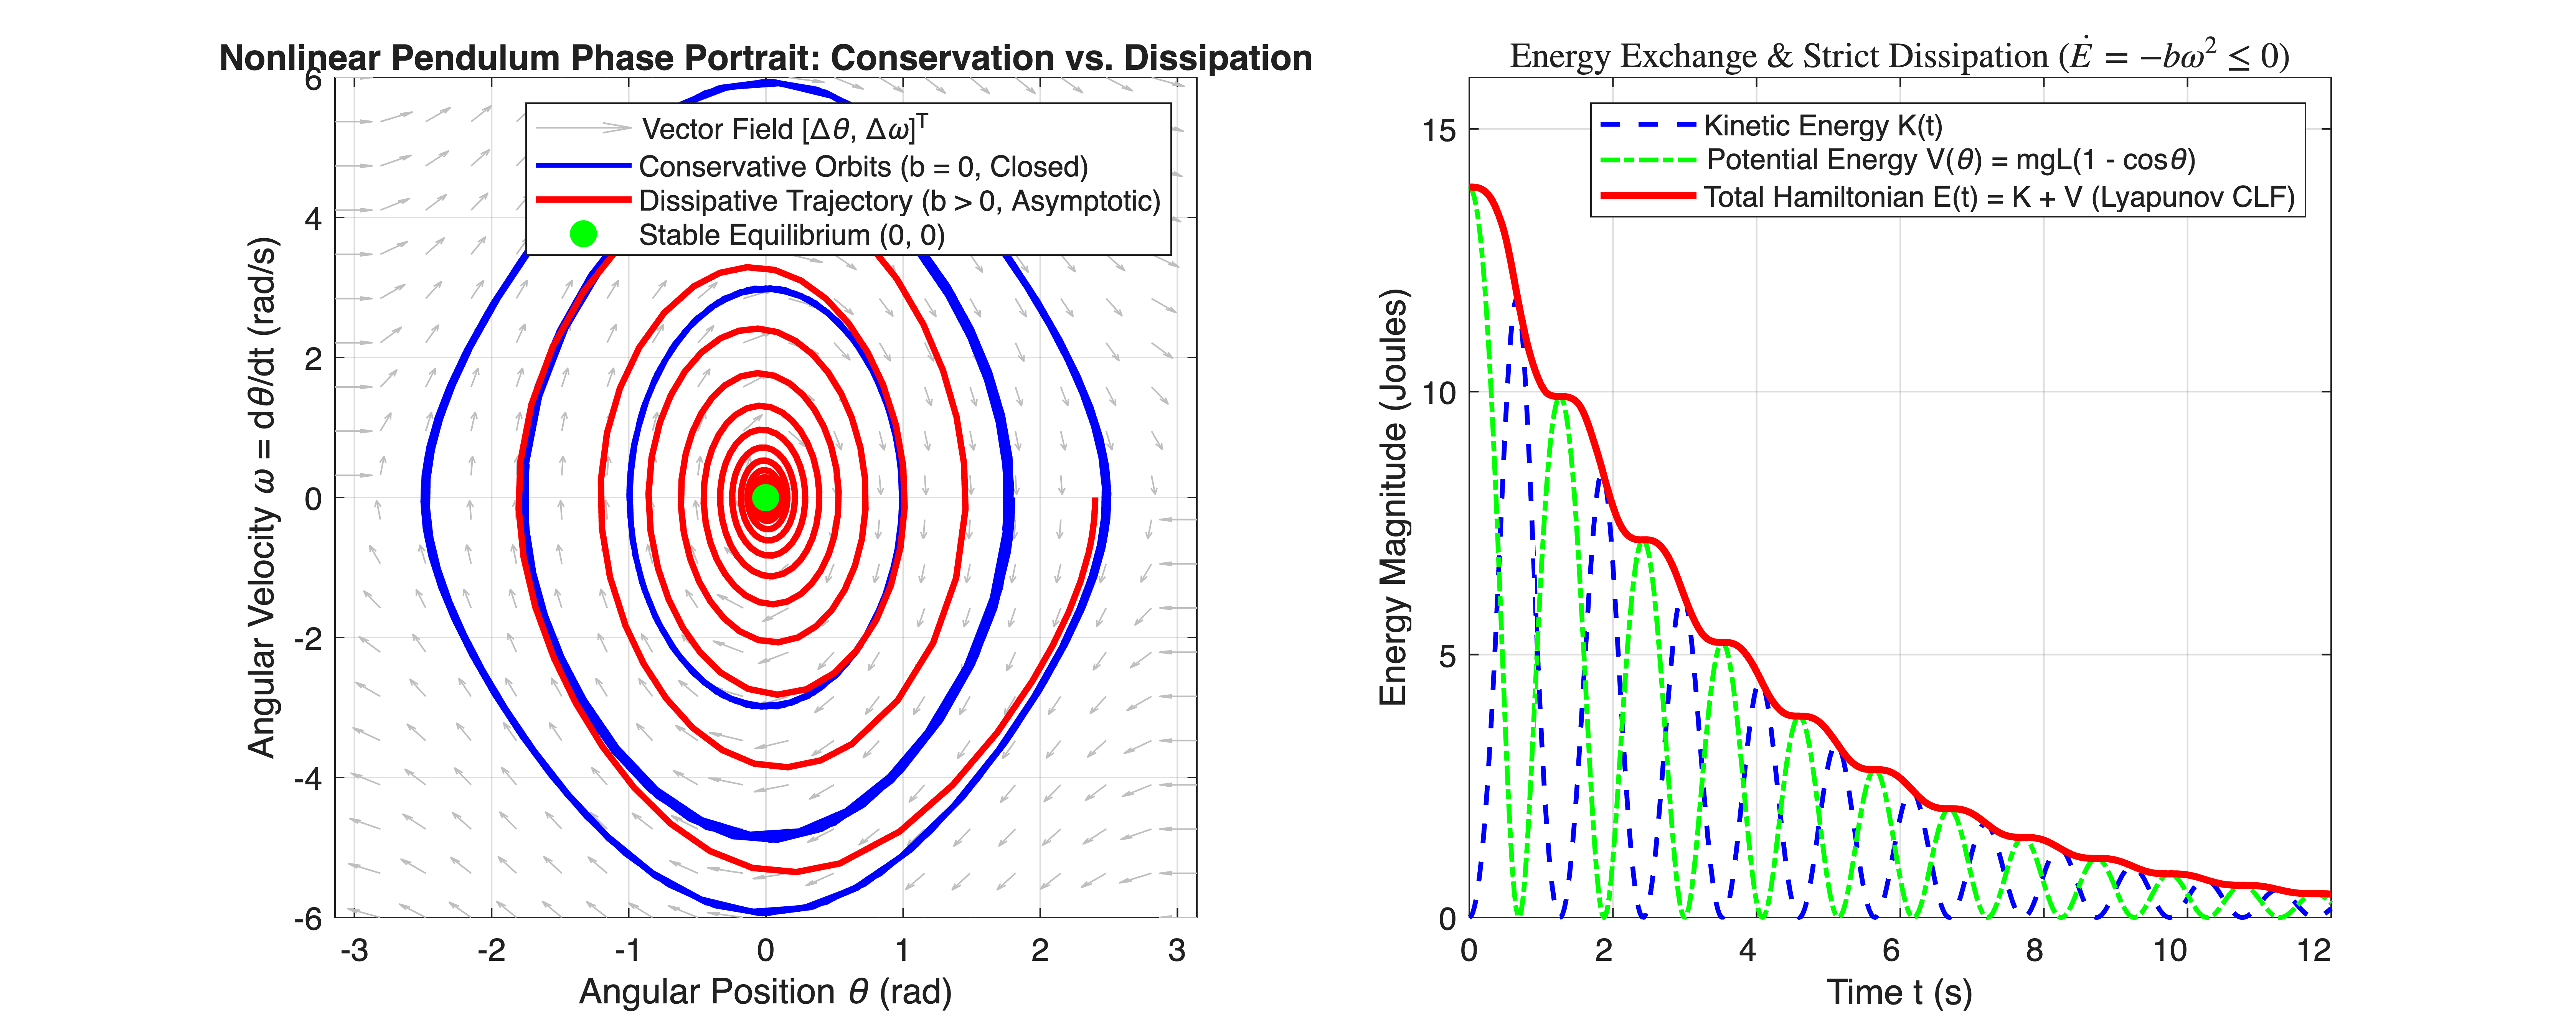

In [1]:
%% MIT 18.01 Lecture 25: Nonlinear Pendulum Dynamics, Work & Energy Simulation
% MBD Concept Mapping: The gravitational work integral derived in lecture forms
% the nonlinear potential energy function V(theta) = m*g*L*(1 - cos(theta)).
% This energy directly acts as the Hamiltonian and Lyapunov candidate function,
% establishing asymptotic stability via energy dissipation in passivity-based control.


clear; clc; close all;


%% System Physical Parameters
m_mass = 1.0;          % Pendulum bob mass (kg)
L_length = 1.0;        % Pendulum rod length (m)
g_accel = 9.81;        % Gravitational acceleration (m/s^2)
b_damping_conservative = 0.0; % Zero damping (Conservative system)
b_damping_dissipative  = 0.3; % Viscous friction coefficient (N*s/m)


% Nonlinear State-Space ODE: [dx1/dt; dx2/dt] = [x2; -(g/L)*sin(x1) - (b/(m*L^2))*x2]
pendulum_ode = @(t, x, b) [x(2); -(g_accel / L_length) * sin(x(1)) - (b / (m_mass * L_length^2)) * x(2)];


figure('Color', 'w', 'Position', [100, 100, 1250, 500]);


%% Subplot 1: Phase Portrait (State Trajectories in Phase Plane)
subplot(1, 2, 1);
theta_init_grid = [-2.5, -1.8, -1.0, 1.0, 1.8, 2.5];
t_span = [0, 15];


% 1. Plot Vector Direction Field (Conservative case)
[TH, W] = meshgrid(linspace(-pi, pi, 20), linspace(-6, 6, 20));
dTH = W;
dW = -(g_accel / L_length) * sin(TH);
norm_quiver = sqrt(dTH.^2 + dW.^2) + 1e-5;
quiver(TH, W, dTH./norm_quiver, dW./norm_quiver, 0.4, 'Color', [0.75, 0.75, 0.75], ...
    'DisplayName', 'Vector Field [\Delta\theta, \Delta\omega]^T'); hold on;


% 2. Conservative Trajectories (Closed periodic orbits)
for k = 1:length(theta_init_grid)
    x0 = [theta_init_grid(k); 0.0];
    [~, X_cons] = ode45(@(t, x) pendulum_ode(t, x, b_damping_conservative), t_span, x0);
    if k == 1
        plot(X_cons(:, 1), X_cons(:, 2), 'b-', 'LineWidth', 1.5, ...
            'DisplayName', 'Conservative Orbits (b = 0, Closed)');
    else
        plot(X_cons(:, 1), X_cons(:, 2), 'b-', 'LineWidth', 1.5, 'HandleVisibility', 'off');
    end
end


% 3. Dissipative Trajectory (Spiraling to stable origin)
[~, X_diss] = ode45(@(t, x) pendulum_ode(t, x, b_damping_dissipative), [0, 25], [2.4; 0.0]);
plot(X_diss(:, 1), X_diss(:, 2), 'r-', 'LineWidth', 2.0, ...
    'DisplayName', 'Dissipative Trajectory (b > 0, Asymptotic)');
plot(0, 0, 'go', 'MarkerSize', 8, 'MarkerFaceColor', 'g', 'DisplayName', 'Stable Equilibrium (0, 0)');


grid on;
xlim([-pi, pi]); ylim([-6, 6]);
xlabel('Angular Position \theta (rad)');
ylabel('Angular Velocity \omega = d\theta/dt (rad/s)');
title('Nonlinear Pendulum Phase Portrait: Conservation vs. Dissipation');
legend('Location', 'northeast');


%% Subplot 2: Energy Conservation & Monotonic Dissipation Profile
subplot(1, 2, 2);
t_sim = linspace(0, 12, 500);
[T_out, X_state] = ode45(@(t, x) pendulum_ode(t, x, b_damping_dissipative), t_sim, [2.0; 0.0]);


theta_t = X_state(:, 1);
omega_t = X_state(:, 2);


% Kinetic Energy: K = 0.5 * m * (L * omega)^2
% Potential Energy derived in Lecture 25: V = m * g * L * (1 - cos(theta))
K_energy = 0.5 * m_mass * (L_length^2) * (omega_t.^2);
V_energy = m_mass * g_accel * L_length * (1.0 - cos(theta_t));
E_total  = K_energy + V_energy;


plot(T_out, K_energy, 'b--', 'LineWidth', 1.5, 'DisplayName', 'Kinetic Energy K(t)'); hold on;
plot(T_out, V_energy, 'g-.', 'LineWidth', 1.5, 'DisplayName', 'Potential Energy V(\theta) = mgL(1 - cos\theta)');
plot(T_out, E_total,  'r-',  'LineWidth', 2.2, 'DisplayName', 'Total Hamiltonian E(t) = K + V (Lyapunov CLF)');


grid on;
xlim([0, 12]); ylim([0, max(E_total)*1.15]);
xlabel('Time t (s)');
ylabel('Energy Magnitude (Joules)');
title('Energy Exchange & Strict Dissipation ($\dot{E} = -b\omega^2 \le 0$)', 'Interpreter', 'latex');
legend('Location', 'northeast');